## Импорты и настройки


In [1]:
import random
import re
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 13
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

TOKEN_RE = re.compile(r"[a-zA-Z']+")
print(f"Device: {DEVICE}")


Device: cpu


## Общие функции


In [2]:
def plot_history(history: dict[str, list[float]], title: str, show_accuracy: bool = True) -> None:
    cols = 2 if show_accuracy else 1
    fig, axes = plt.subplots(1, cols, figsize=(10 if show_accuracy else 5, 3))
    if not show_accuracy:
        axes = [axes]

    axes[0].plot(history["loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{title}: loss")
    axes[0].set_xlabel("epoch")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    if show_accuracy:
        axes[1].plot(history["acc"], label="train")
        axes[1].plot(history["val_acc"], label="validation")
        axes[1].set_title(f"{title}: accuracy")
        axes[1].set_xlabel("epoch")
        axes[1].grid(True, alpha=0.3)
        axes[1].legend()

    plt.tight_layout()
    plt.show()


## Этап 1. IMDB: двунаправленная LSTM


In [3]:
def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(text.lower())


def read_imdb(zip_path: Path, max_docs_per_class: int = 900) -> tuple[list[str], list[int]]:
    if not zip_path.exists():
        raise FileNotFoundError(f"Не найден архив IMDB: {zip_path}")

    texts = []
    labels = []
    with zipfile.ZipFile(zip_path) as archive:
        for split in ["train", "test"]:
            for label_name, label in [("neg", 0), ("pos", 1)]:
                prefix = f"aclImdb/{split}/{label_name}/"
                names = [n for n in archive.namelist() if n.startswith(prefix) and n.endswith(".txt")]
                names = [n for n in names if "/._" not in n]
                for name in names[:max_docs_per_class]:
                    texts.append(archive.read(name).decode("utf-8", errors="ignore"))
                    labels.append(label)
    return texts, labels


def make_vocab(texts: list[str], max_words: int = 12000) -> dict[str, int]:
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))
    vocab = {"<pad>": 0, "<unk>": 1}
    for word, _ in counter.most_common(max_words - 2):
        vocab[word] = len(vocab)
    return vocab


In [4]:
class TextDataset(Dataset):
    def __init__(self, texts: list[str], labels: list[int], vocab: dict[str, int], max_len: int = 180):
        self.labels = labels
        self.samples = []
        for text in texts:
            ids = [vocab.get(token, 1) for token in tokenize(text)[:max_len]]
            self.samples.append(torch.tensor(ids or [1], dtype=torch.long))

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.samples[index], torch.tensor(float(self.labels[index]), dtype=torch.float32)


def collate_batch(batch: list[tuple[torch.Tensor, torch.Tensor]]) -> tuple[torch.Tensor, torch.Tensor]:
    texts, labels = zip(*batch)
    return pad_sequence(texts, batch_first=True, padding_value=0), torch.stack(labels)


In [5]:
class BiLstmClassifier(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int = 64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.LSTM(
            input_size=embed_dim,
            hidden_size=32,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2,
        )
        self.output = nn.Linear(64, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        embedded = self.embedding(x)
        _, (hidden, _) = self.rnn(embedded)
        last_forward = hidden[-2]
        last_backward = hidden[-1]
        return self.output(torch.cat([last_forward, last_backward], dim=1)).squeeze(1)


class ConvTextClassifier(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int = 64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.features = nn.Sequential(
            nn.Conv1d(embed_dim, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.AdaptiveMaxPool1d(1),
        )
        self.output = nn.Linear(64, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        embedded = self.embedding(x).transpose(1, 2)
        features = self.features(embedded).squeeze(-1)
        return self.output(features).squeeze(1)


In [6]:
def evaluate_binary(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            total_loss += float(criterion(logits, y).item()) * len(x)
            correct += int(((torch.sigmoid(logits) >= 0.5).float() == y).sum().item())
            total += len(x)
    return total_loss / total, correct / total


def train_binary(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, epochs: int) -> dict[str, list[float]]:
    model.to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            total_loss += float(loss.item()) * len(x)
            correct += int(((torch.sigmoid(logits) >= 0.5).float() == y).sum().item())
            total += len(x)

        val_loss, val_acc = evaluate_binary(model, val_loader, criterion)
        history["loss"].append(total_loss / total)
        history["acc"].append(correct / total)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"epoch {epoch + 1:02d}: loss={history['loss'][-1]:.4f}, acc={history['acc'][-1]:.4f}, val_acc={val_acc:.4f}")

    return history


In [7]:
texts, labels = read_imdb(Path("../IMDB/aclImdb.zip"), max_docs_per_class=900)
vocab = make_vocab(texts, max_words=12000)
text_dataset = TextDataset(texts, labels, vocab, max_len=180)

train_size = int(0.7 * len(text_dataset))
val_size = int(0.15 * len(text_dataset))
test_size = len(text_dataset) - train_size - val_size
text_train, text_val, text_test = random_split(
    text_dataset, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(SEED)
)

text_train_loader = DataLoader(text_train, batch_size=64, shuffle=True, collate_fn=collate_batch)
text_val_loader = DataLoader(text_val, batch_size=128, shuffle=False, collate_fn=collate_batch)
text_test_loader = DataLoader(text_test, batch_size=128, shuffle=False, collate_fn=collate_batch)

print(f"Texts: {len(text_dataset)}, vocab: {len(vocab)}")


Texts: 3600, vocab: 12000


epoch 01: loss=0.6929, acc=0.5032, val_acc=0.5167
epoch 02: loss=0.6837, acc=0.5853, val_acc=0.5556
epoch 03: loss=0.6528, acc=0.6294, val_acc=0.6111
epoch 04: loss=0.5990, acc=0.6968, val_acc=0.6407
epoch 05: loss=0.5035, acc=0.7663, val_acc=0.6648
epoch 06: loss=0.4073, acc=0.8238, val_acc=0.6519
epoch 07: loss=0.3129, acc=0.8718, val_acc=0.6759
epoch 08: loss=0.2236, acc=0.9131, val_acc=0.6870
epoch 09: loss=0.1678, acc=0.9409, val_acc=0.7222
epoch 10: loss=0.1547, acc=0.9433, val_acc=0.7019
epoch 11: loss=0.0883, acc=0.9742, val_acc=0.7241
epoch 12: loss=0.0586, acc=0.9841, val_acc=0.7315
epoch 13: loss=0.0424, acc=0.9901, val_acc=0.7259
epoch 14: loss=0.0512, acc=0.9849, val_acc=0.7407
epoch 15: loss=0.0292, acc=0.9944, val_acc=0.7315
epoch 16: loss=0.0238, acc=0.9952, val_acc=0.7444
epoch 17: loss=0.0231, acc=0.9960, val_acc=0.7370
epoch 18: loss=0.0174, acc=0.9976, val_acc=0.7500
epoch 19: loss=0.0162, acc=0.9980, val_acc=0.7352
epoch 20: loss=0.0153, acc=0.9980, val_acc=0.7426


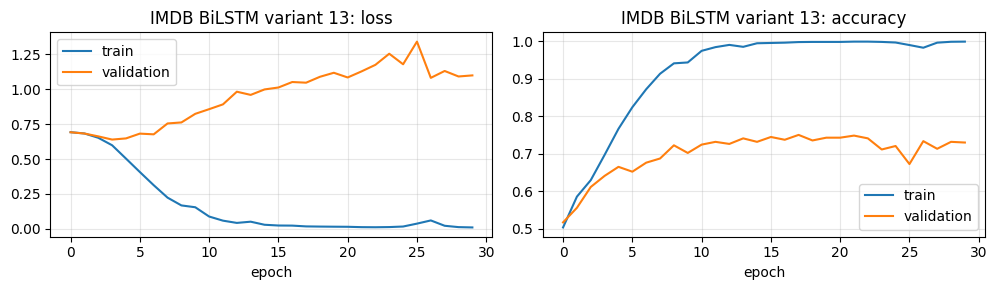

In [8]:
bilstm_model = BiLstmClassifier(len(vocab), embed_dim=64)
BILSTM_EPOCHS = 30
bilstm_history = train_binary(bilstm_model, text_train_loader, text_val_loader, epochs=BILSTM_EPOCHS)

bilstm_loss, bilstm_acc = evaluate_binary(bilstm_model, text_test_loader, nn.BCEWithLogitsLoss())
print(f"BiLSTM variant: test_loss={bilstm_loss:.4f}, test_acc={bilstm_acc:.4f}")
plot_history(bilstm_history, "IMDB BiLSTM variant 13")


## Сравнение с одномерной сверточной сетью


epoch 01: loss=0.6963, acc=0.5067, val_acc=0.4852
epoch 02: loss=0.6867, acc=0.5488, val_acc=0.4759
epoch 03: loss=0.6748, acc=0.5813, val_acc=0.4778
epoch 04: loss=0.6107, acc=0.6857, val_acc=0.6111
epoch 05: loss=0.4539, acc=0.7921, val_acc=0.6556
epoch 06: loss=0.2710, acc=0.9024, val_acc=0.7185
epoch 07: loss=0.1037, acc=0.9845, val_acc=0.7167
epoch 08: loss=0.0311, acc=0.9984, val_acc=0.7130
epoch 09: loss=0.0117, acc=1.0000, val_acc=0.7259
epoch 10: loss=0.0047, acc=1.0000, val_acc=0.7389
epoch 11: loss=0.0029, acc=1.0000, val_acc=0.7370
epoch 12: loss=0.0019, acc=1.0000, val_acc=0.7370
epoch 13: loss=0.0014, acc=1.0000, val_acc=0.7426
epoch 14: loss=0.0011, acc=1.0000, val_acc=0.7315
epoch 15: loss=0.0008, acc=1.0000, val_acc=0.7426
epoch 16: loss=0.0007, acc=1.0000, val_acc=0.7463
epoch 17: loss=0.0006, acc=1.0000, val_acc=0.7481
epoch 18: loss=0.0005, acc=1.0000, val_acc=0.7519
epoch 19: loss=0.0004, acc=1.0000, val_acc=0.7481
epoch 20: loss=0.0003, acc=1.0000, val_acc=0.7481


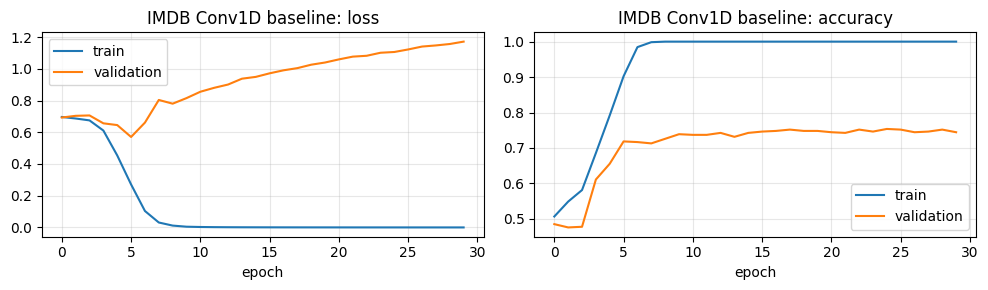

In [9]:
conv_text_model = ConvTextClassifier(len(vocab), embed_dim=64)
CONV_TEXT_EPOCHS = 30
conv_text_history = train_binary(conv_text_model, text_train_loader, text_val_loader, epochs=CONV_TEXT_EPOCHS)

conv_loss, conv_acc = evaluate_binary(conv_text_model, text_test_loader, nn.BCEWithLogitsLoss())
print(f"Conv1D baseline: test_loss={conv_loss:.4f}, test_acc={conv_acc:.4f}")
plot_history(conv_text_history, "IMDB Conv1D baseline")


## Этап 2. Прогноз температуры Jena Climate


In [10]:
def read_jena(zip_path: Path) -> pd.DataFrame:
    if not zip_path.exists():
        raise FileNotFoundError(f"Не найден архив Jena Climate: {zip_path}")
    with zipfile.ZipFile(zip_path) as archive:
        csv_name = next(name for name in archive.namelist() if name.endswith("jena_climate_2009_2016.csv"))
        with archive.open(csv_name) as file:
            return pd.read_csv(file)


jena = read_jena(Path("../Jena Climate/jena_climate.zip"))
print(jena.shape)
jena.head()


(420451, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


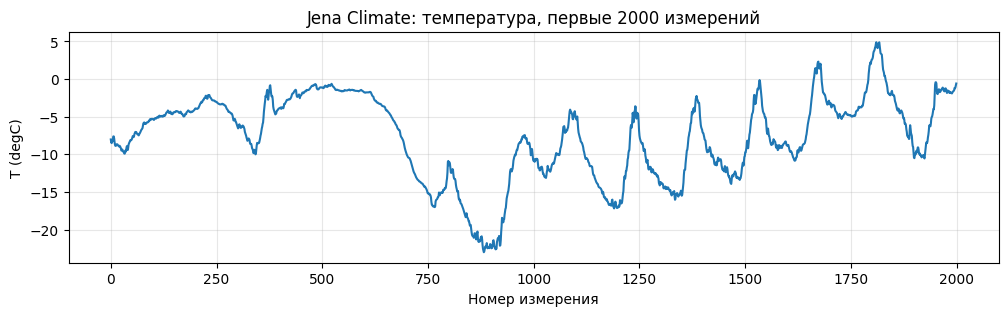

In [11]:
plt.figure(figsize=(12, 3))
plt.plot(jena["T (degC)"].values[:2000])
plt.title("Jena Climate: температура, первые 2000 измерений")
plt.xlabel("Номер измерения")
plt.ylabel("T (degC)")
plt.grid(True, alpha=0.3)
plt.show()


In [12]:
feature_frame = jena.drop(columns=["Date Time"])
feature_names = list(feature_frame.columns)
target_index = feature_names.index("T (degC)")
raw_values = feature_frame.values.astype("float32")

train_border = int(0.7 * len(raw_values))
mean = raw_values[:train_border].mean(axis=0)
std = raw_values[:train_border].std(axis=0)
values = (raw_values - mean) / std
target = raw_values[:, target_index]

LOOKBACK = 1440      # 10 дней назад при шаге исходных данных 10 минут
DELAY = 144          # прогноз на 1 день вперед
STEP = 6             # одно значение в час
BATCH_SIZE = 128
MAX_SAMPLES = 2500


def make_climate_tensors(start: int, end: int, max_samples: int) -> tuple[torch.Tensor, torch.Tensor]:
    last_start = min(end - DELAY, len(values) - DELAY)
    indices = np.arange(start + LOOKBACK, last_start)
    if len(indices) > max_samples:
        rng = np.random.default_rng(SEED)
        indices = np.sort(rng.choice(indices, size=max_samples, replace=False))

    samples = np.stack([values[i - LOOKBACK:i:STEP] for i in indices]).astype("float32")
    labels = target[indices + DELAY].astype("float32").reshape(-1, 1)
    return torch.tensor(samples), torch.tensor(labels)


x_train, y_train = make_climate_tensors(0, train_border, MAX_SAMPLES)
x_val, y_val = make_climate_tensors(train_border, int(0.85 * len(values)), MAX_SAMPLES // 2)
x_test, y_test = make_climate_tensors(int(0.85 * len(values)), len(values), MAX_SAMPLES // 2)

climate_train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
climate_val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
climate_test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

print(x_train.shape, x_val.shape, x_test.shape)


torch.Size([2500, 240, 14]) torch.Size([1250, 240, 14]) torch.Size([1250, 240, 14])


In [13]:
class ClimateLstm(nn.Module):
    def __init__(self, input_size: int):
        super().__init__()
        self.rnn = nn.LSTM(input_size, 64, num_layers=3, batch_first=True, bidirectional=True, dropout=0.3)
        self.output = nn.Linear(128, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        _, (hidden, _) = self.rnn(x)
        return self.output(torch.cat([hidden[-2], hidden[-1]], dim=1))


class ClimateConvLstm(nn.Module):
    def __init__(self, input_size: int):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(input_size, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.rnn = nn.LSTM(32, 64, num_layers=3, batch_first=True, bidirectional=True, dropout=0.3)
        self.output = nn.Linear(128, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.conv(x.transpose(1, 2)).transpose(1, 2)
        _, (hidden, _) = self.rnn(features)
        return self.output(torch.cat([hidden[-2], hidden[-1]], dim=1))


In [14]:
def evaluate_regression(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    total_abs = 0.0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x)
            total_loss += float(criterion(pred, y).item()) * len(x)
            total_abs += float(torch.abs(pred - y).sum().item())
            total += len(x)
    return total_loss / total, total_abs / total


def train_regression(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, epochs: int) -> dict[str, list[float]]:
    model.to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {"loss": [], "val_loss": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            pred = model(x)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()
            total_loss += float(loss.item()) * len(x)
            total += len(x)

        val_loss, val_mae = evaluate_regression(model, val_loader, criterion)
        history["loss"].append(total_loss / total)
        history["val_loss"].append(val_loss)
        print(f"epoch {epoch + 1:02d}: loss={history['loss'][-1]:.4f}, val_loss={val_loss:.4f}, val_mae={val_mae:.2f}")

    return history


epoch 01: loss=136.1179, val_loss=94.2705, val_mae=7.75
epoch 02: loss=62.9177, val_loss=48.2765, val_mae=5.45
epoch 03: loss=40.4055, val_loss=36.0964, val_mae=4.69
epoch 04: loss=32.8928, val_loss=28.6013, val_mae=4.14
epoch 05: loss=26.4692, val_loss=23.1269, val_mae=3.63
epoch 06: loss=22.5773, val_loss=19.4638, val_mae=3.35
epoch 07: loss=19.7155, val_loss=17.5010, val_mae=3.18
epoch 08: loss=17.6892, val_loss=16.8476, val_mae=3.15
epoch 09: loss=16.1750, val_loss=15.6616, val_mae=3.02
epoch 10: loss=16.0633, val_loss=15.2411, val_mae=2.99
epoch 11: loss=14.4447, val_loss=15.7641, val_mae=3.10
epoch 12: loss=13.9022, val_loss=15.0453, val_mae=3.03
epoch 13: loss=13.2006, val_loss=14.4081, val_mae=2.92
epoch 14: loss=13.0777, val_loss=14.5079, val_mae=2.97
epoch 15: loss=12.6615, val_loss=15.8403, val_mae=3.18
epoch 16: loss=13.1857, val_loss=13.2995, val_mae=2.78
epoch 17: loss=12.4738, val_loss=12.7983, val_mae=2.76
epoch 18: loss=11.7390, val_loss=12.8215, val_mae=2.79
epoch 19:

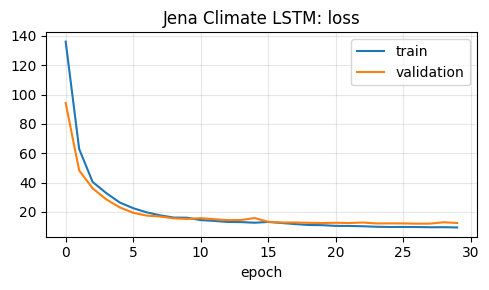

In [15]:
climate_model = ClimateLstm(input_size=x_train.shape[-1])
CLIMATE_EPOCHS = 30
climate_history = train_regression(climate_model, climate_train_loader, climate_val_loader, epochs=CLIMATE_EPOCHS)

climate_test_loss, climate_test_mae = evaluate_regression(climate_model, climate_test_loader, nn.MSELoss())
print(f"Jena LSTM: test_loss={climate_test_loss:.4f}, test_mae={climate_test_mae:.2f}")
plot_history(climate_history, "Jena Climate LSTM", show_accuracy=False)


## Сравнение с Conv1D + LSTM


epoch 01: loss=137.6875, val_loss=98.3211, val_mae=8.05
epoch 02: loss=79.6773, val_loss=62.1584, val_mae=6.55
epoch 03: loss=72.1788, val_loss=57.2504, val_mae=6.26
epoch 04: loss=46.0576, val_loss=35.1184, val_mae=4.58
epoch 05: loss=32.8251, val_loss=27.1972, val_mae=4.00
epoch 06: loss=27.4771, val_loss=21.2778, val_mae=3.42
epoch 07: loss=23.0552, val_loss=18.4715, val_mae=3.14
epoch 08: loss=19.5304, val_loss=16.5044, val_mae=3.01
epoch 09: loss=17.5753, val_loss=16.5354, val_mae=3.13
epoch 10: loss=15.6935, val_loss=14.8475, val_mae=2.89
epoch 11: loss=14.6483, val_loss=14.2773, val_mae=2.91
epoch 12: loss=13.5157, val_loss=13.5323, val_mae=2.77
epoch 13: loss=12.8825, val_loss=13.2960, val_mae=2.81
epoch 14: loss=12.2704, val_loss=12.8911, val_mae=2.76
epoch 15: loss=12.0872, val_loss=13.8240, val_mae=2.94
epoch 16: loss=11.9635, val_loss=12.2577, val_mae=2.64
epoch 17: loss=11.2836, val_loss=13.3611, val_mae=2.88
epoch 18: loss=11.2003, val_loss=12.1810, val_mae=2.70
epoch 19:

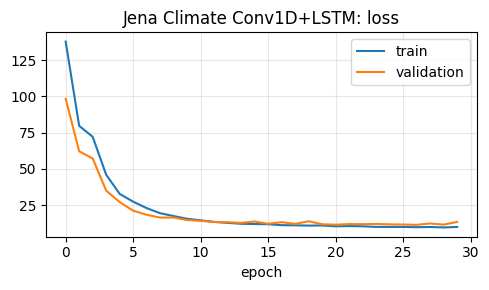

In [16]:
climate_conv_model = ClimateConvLstm(input_size=x_train.shape[-1])
conv_climate_history = train_regression(climate_conv_model, climate_train_loader, climate_val_loader, epochs=CLIMATE_EPOCHS)

conv_climate_loss, conv_climate_mae = evaluate_regression(climate_conv_model, climate_test_loader, nn.MSELoss())
print(f"Jena Conv1D+LSTM: test_loss={conv_climate_loss:.4f}, test_mae={conv_climate_mae:.2f}")
plot_history(conv_climate_history, "Jena Climate Conv1D+LSTM", show_accuracy=False)
